# Steane logical-plus state $|+\rangle_L$ preparation

- `dual`: a Hadamard-dual construction derived from Fig. 6, using CCZ feedback.
- `reference`: the logical-zero preparation in Fig. 6 followed by transversal H on the seven data qubits.

Source retained from the original file: [Heussen et al., PRX Quantum 5, 010333 (2024), Fig. 6](https://doi.org/10.1103/PRXQuantum.5.010333).
The logical-plus circuits here are constructions based on that figure.

This notebook constructs, displays, and optionally exports the circuits, and performs exact checks on
**the ideal Clifford encoding stage of `dual` and its appended logical-X readout**.
It does not include state simulation of the complete CCZ/CCX protocol, noisy sampling, fault enumeration, or a fault-tolerance proof.

## 1. Dependencies and qubit indexing

Requires `stim`, `bloqade-tsim`, and IPython. The commented installation command below lists the versions used for validation.
Uncomment it only if dependencies are missing, then restart the kernel.

| Program index | Role |
|---|---|
| q0–q6 | Data qubits, corresponding to paper qubits 1–7 |
| q7 | Flag ancilla |
| q8 | Check ancilla |
| q9 | Used only for the verification readout below |

`R` resets a qubit to $|0\rangle$. Each preparation circuit explicitly initializes all nine qubits and resets q7 and q8 at the end;
preparation produces no measurement records.

In [1]:
# %pip install stim==1.16.0 bloqade-tsim==0.1.5 ipython

from importlib.metadata import version
from pathlib import Path
from IPython.display import Markdown, display
import stim
import tsim

print({name: version(name) for name in ("stim", "bloqade-tsim")})

{'stim': '1.16.0', 'bloqade-tsim': '0.1.5'}


## 2. Two complete preparation circuits

`ENCODERS` contains initialization and the Clifford encoding stages; `PROGRAMS` appends the check mappings,
coherent feedback, and ancilla resets.
Each `CX` line is read as successive control–target pairs, preserving the order in the original implementation.
`TICK` marks stage boundaries and does not specify hardware gate durations.

`dual` reverses the encoding CX directions; the flag/check ancillas control CCZ through X-type mappings and ancilla H gates.
`reference` retains the original encoding directions and Z-type mappings, applies CCX, and then applies transversal H.

In [2]:
ENCODERS = {
    "dual": stim.Circuit("""
        R 0 1 2 3 4 5 6 7 8
        TICK
        H 2 4 5 6 7 8
        CX 4 0 2 1 5 3 6 0 4 3 5 1 2 0 6 5
        TICK
    """),
    "reference": stim.Circuit("""
        R 0 1 2 3 4 5 6 7 8
        TICK
        H 0 1 3
        CX 0 4 1 2 3 5 0 6 3 4 1 5 0 2 5 6
        TICK
    """),
}

PROGRAMS = {
    "dual": str(ENCODERS["dual"]) + """
        CX 7 4 7 2 7 5
        TICK
        CX 8 0 8 1 8 3 8 6
        TICK
        H 7 8
        TICK
        CCZ 7 8 6
        TICK
        R 7 8
        TICK
    """,
    "reference": str(ENCODERS["reference"]) + """
        CX 4 7 2 7 5 7
        TICK
        CX 0 8 1 8 3 8 6 8
        TICK
        CCX 7 8 6
        TICK
        R 7 8
        TICK
        H 0 1 2 3 4 5 6
        TICK
    """,
}


def build_circuit(variant="dual"):
    """Return a complete nine-qubit Tsim preparation circuit."""
    if variant not in PROGRAMS:
        raise ValueError("variant must be 'dual' or 'reference'")
    return tsim.Circuit(PROGRAMS[variant])


circuits = {name: build_circuit(name) for name in PROGRAMS}
for name, circuit in circuits.items():
    assert circuit.num_qubits == 9 and circuit.num_measurements == 0
    assert tsim.Circuit(str(circuit)) == circuit
    print(f"{name}: {circuit.num_qubits} qubits, {circuit.num_measurements} measurements")

dual: 9 qubits, 0 measurements
reference: 9 qubits, 0 measurements


## 3. Complete Tsim circuit diagrams

The cell below calls `diagram("timeline-svg", zoomable=False)` directly, displaying the complete circuits
from initialization through final cleanup/transversal H.
Tsim decomposes native CCZ/CCX gates into Clifford+T operations; see `PROGRAMS` above for the native gates and their positions.

Export the complete program using `str(circuit)`. **Do not run `circuit.stim_circuit` with an ordinary Stim sampler**:
the T gates represented there must not be interpreted as ordinary Stim Clifford gates.

### dual

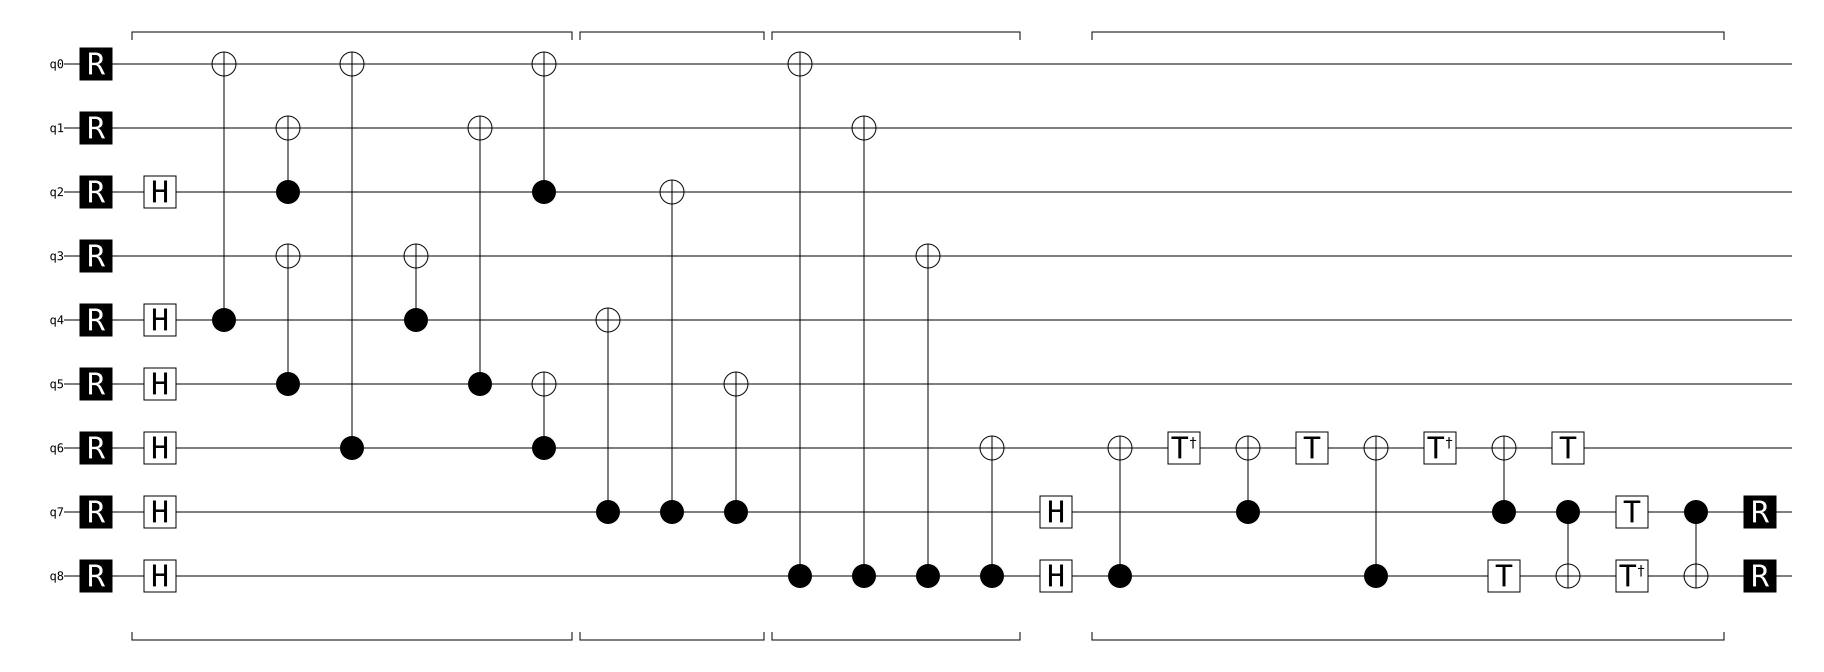

### reference

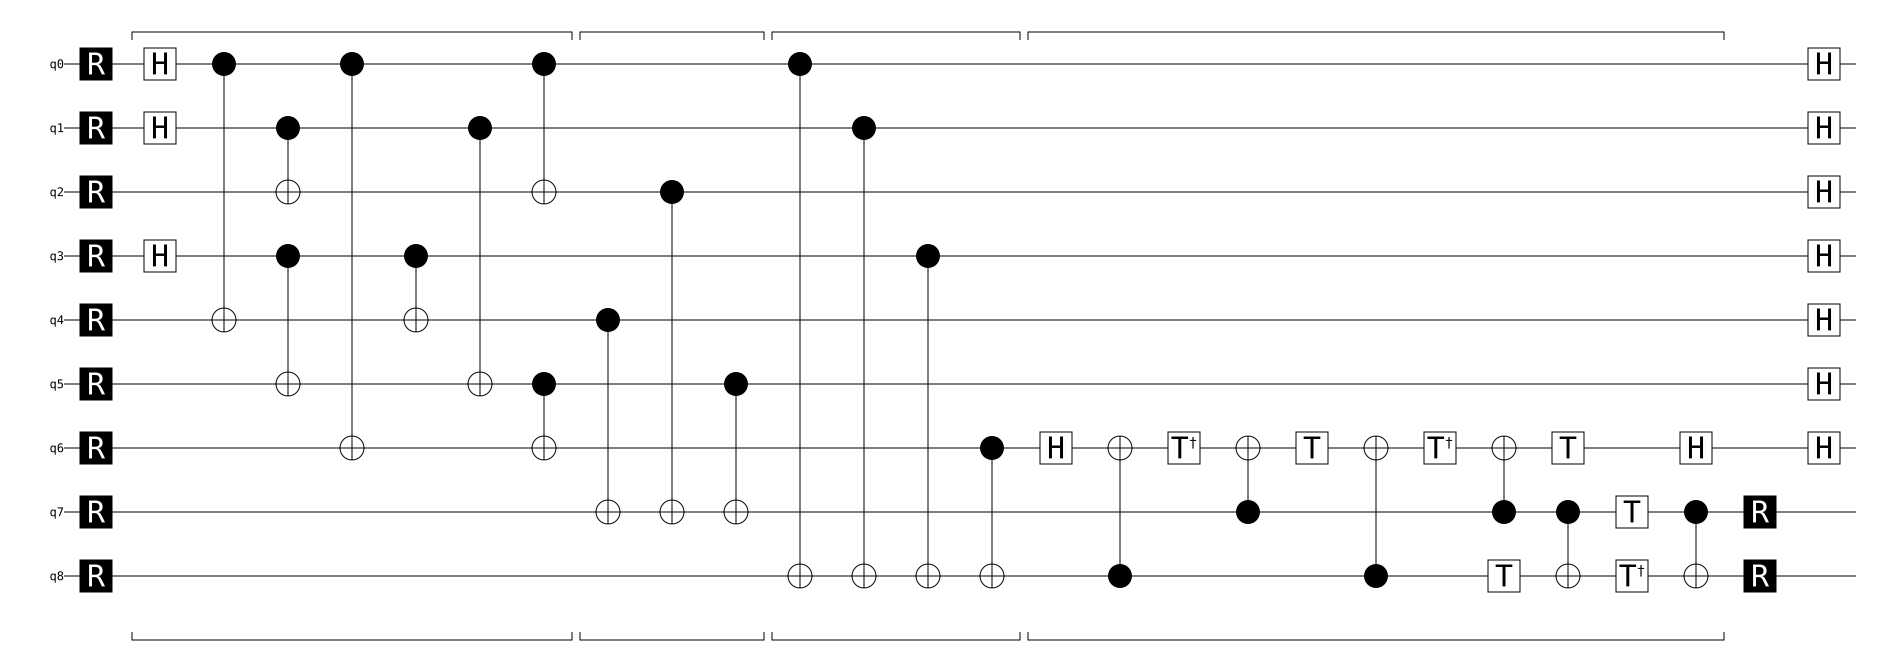

In [3]:
diagrams = {}
for name, circuit in circuits.items():
    display(Markdown(f"### {name}"))
    # Preserve the dagger as an ASCII XML entity for GitHub's SVG preview.
    svg = str(circuit.diagram("timeline-svg", zoomable=False)).replace("\u2020", "&#x2020;")
    if "ERR" in svg or "I_ERROR" in svg:
        raise RuntimeError(f"{name}: Tsim diagram contains an unresolved gate label")
    diagrams[name] = svg
    display({"image/svg+xml": svg}, raw=True)

## 4. Logical-X check of the ideal Clifford encoding stage

In this convention, one can choose $X_L=X_2X_4X_5$ (program indices, corresponding to paper qubits 3, 5, and 6).
It equals the seven-qubit logical X multiplied by the X stabilizer supported on q0, q1, q3, and q6.

Initialize q9 in $|+\rangle$, use it as the control for three CX gates targeting q2, q4, and q5, and then apply H and measure in Z.
Readout bit 0 corresponds to $X_L=+1$. The Stim tableau calculation below evaluates
$\langle X_L\rangle$ after encoding and $\langle Z_9\rangle$ immediately before measurement exactly, without finite-shot sampling.

This diagram covers **initialization through the verification measurement for the `dual` encoding stage**;
it does not include the subsequent CCZ feedback.
The verification measurement is an additional probe, separate from the measurement-free preparation protocol above.

Exact <X2 X4 X5> = +1
Exact <Z9> before measurement = +1; readout bit = 0


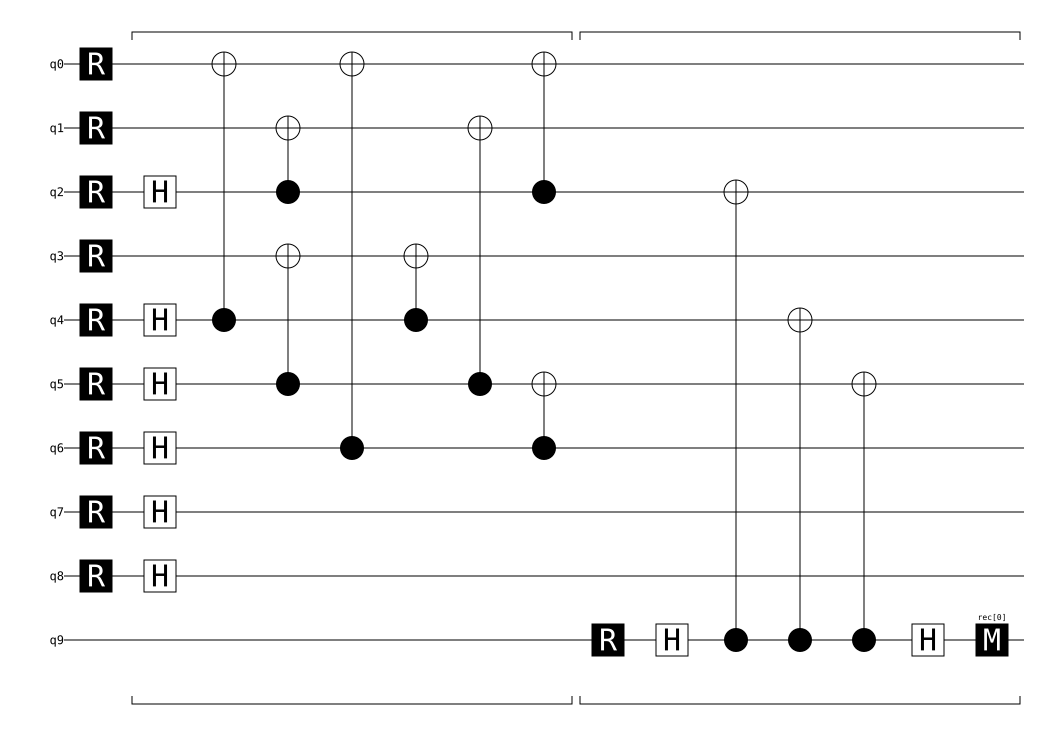

In [4]:
encoder = ENCODERS["dual"]
x_readout = encoder + stim.Circuit("""
    R 9
    H 9
    CX 9 2 9 4 9 5
    H 9
    M 9
""")

sim = stim.TableauSimulator()
sim.do(encoder)
logical_x = sim.peek_observable_expectation(stim.PauliString("IIXIXXI"))
assert logical_x == 1, "Expected logical X = +1 after ideal encoding"

sim = stim.TableauSimulator()
sim.do(x_readout[:-1])  # Stop immediately before the final measurement.
readout_z = sim.peek_z(9)
assert readout_z == 1, "Expected deterministic readout bit 0"

print(f"Exact <X2 X4 X5> = {logical_x:+d}")
print(f"Exact <Z9> before measurement = {readout_z:+d}; readout bit = 0")
display(x_readout.diagram("timeline-svg"))

## 5. Optional circuit export

The notebook contains the outputs and circuit diagrams and can be shared on its own.
Set `SAVE_FILES` to `True` only if separate circuit files are needed.
The output directory is relative to the working directory at runtime; no additional files are created by default.

In [5]:
SAVE_FILES = False
OUTPUT_DIR = Path("logical_plus_output")

if SAVE_FILES:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    for name, circuit in circuits.items():
        stem = OUTPUT_DIR / f"logical_plus_{name}"
        stem.with_suffix(".tsim").write_text(str(circuit) + "\n", encoding="utf-8")
        stem.with_suffix(".svg").write_text(str(diagrams[name]), encoding="utf-8")
    print(f"Saved Tsim programs and diagrams to {OUTPUT_DIR.resolve()}")
else:
    print("Export disabled. Set SAVE_FILES = True to save programs and diagrams.")

Export disabled. Set SAVE_FILES = True to save programs and diagrams.
